# STATS 201 Week 3 Methods Lab

**Learning goal.** Distinguish a measurement rule, an unsupervised explanation and a prediction for an unseen case. Use one result to improve your own evaluation plan.

Run the cells in order. This lab uses CPU and publicly reachable datasets. First run the defaults. Then change **one** setting in **Your turn**, rerun the affected cells and explain what changed. The data, table and figures display in the notebook.

| Part | Question | Student choice |
|---|---|---|
| 1 Measurement | How do we turn a stored answer index into a label? | Reason about the two rows before revealing the labels. |
| 2 Explanation | Which requests use similar language? | Try K = 3, 4 or 5. Default 4. |
| 3 Prediction | Will a classifier label an unseen robot frame correctly? | Try all cameras or wrist only. Default all. The decision threshold starts at 0.50. |

Section 4 generates a four-panel **visualization gallery** in Python and saves a PNG. For the Ed check, choose **one** figure or gallery panel, write one interpretation and one check, and provide a Colab viewer link your instructor can open.

In [1]:
# Read and run. These imports work in Colab's standard Python runtime.
import ast
import json
import re
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from io import BytesIO
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image as NotebookImage, display
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

DATA_SERVER = "https://datasets-server.huggingface.co"
ROBOT = "keplerccc/Robo2VLM-1"
WILDCHAT = "heyyjudes/wildchat-creative-only-labeled"
TARGET_IDS = ("14652_q29", "14652_q35")

def read_url(url):
    for attempt in range(3):
        try:
            with urlopen(url, timeout=25) as response:
                return response.read()
        except (URLError, TimeoutError) as error:
            if isinstance(error, HTTPError) and error.code not in {429, 500, 502, 503, 504}:
                raise RuntimeError(f"Hugging Face returned HTTP {error.code}. Rerun the data cell.") from error
            if attempt == 2:
                raise RuntimeError("Hugging Face is unavailable. The saved default outputs can support discussion.") from error
            time.sleep(2 ** attempt)

def page(dataset, offset=0, first=False):
    params = {"dataset": dataset, "config": "default", "split": "train"}
    endpoint = "first-rows" if first else "rows"
    if not first:
        params.update(offset=offset, length=100)
    return json.loads(read_url(f"{DATA_SERVER}/{endpoint}?{urlencode(params)}"))["rows"]

def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=125, bbox_inches="tight")
    plt.close(fig)
    display(NotebookImage(data=buffer.getvalue()))


## 1 Measurement

One Robo2VLM-1 row pairs a robot image with a question and its choices. The task asks whether a robot completed a specific action. The integer in **correct_answer** is an option position, starting at zero. Option order can vary between rows.

$$ y_i=\mathrm{choices}_i[\mathrm{correct\_answer}_i]. $$

Read the choices before running the code. Can two rows with the same number encode different outcomes? Think about what the reference answer can see and what a camera view may miss. The classroom binary task retains the explicit **Yes** and **No** answers. Other answer categories are outside this binary task.

In [2]:
# Read and run. Each row has its own choice order.
def reference_answer(row):
    choices = row["choices"]
    choices = ast.literal_eval(choices) if isinstance(choices, str) else choices
    return choices[row["correct_answer"]]

first_robot = [entry["row"] for entry in page(ROBOT, first=True)]
targets = [next(row for row in first_robot if row["id"].endswith(key)) for key in TARGET_IDS]
measured = pd.DataFrame({
    "Frame": TARGET_IDS,
    "Choices in order": [row["choices"] for row in targets],
    "Answer index": [row["correct_answer"] for row in targets],
    "Decoded reference": [reference_answer(row) for row in targets],
})
display(measured)


Frame,Choices in order,Answer index,Decoded reference
14652_q29,"['Yes', 'Task was not attempted', 'No', 'Cannot be determined']",2,No
14652_q35,"['No', 'Cannot be determined', 'Yes', 'Task was not attempted']",2,Yes


## 2 Explanation with unsupervised learning

Shen (ICML 2025, Appendix A.2) reused WildChat and LMSYS and clustered sentence embeddings following [Zheng et al.'s K-means procedure](https://arxiv.org/abs/2309.11998). The author then reviewed and interpreted themes. This classroom adaptation uses the author's public WildChat-derived table and **TF–IDF** so it can run on CPU. One row is one user request. TF–IDF gives more weight to words that occur in a request and are less common across requests in the slice.

K-means finds centers $\mu_j$ and assignments $z_i$ for the request vectors $x_i$:

$$ \min_{\mu,z}\sum_{i=1}^{n}\lVert x_i-\mu_{z_i}\rVert_2^2. $$

The fit reads **user_prompt**. The published **cluster_id** is used only in the optional after-fit comparison. For a short lesson we take the first 400 rows returned by the API and apply the documented length and text filter. This is an ordered convenience slice of an already selected corpus. We display aggregate terms rather than raw messages. Interpret a theme as a judgment about this slice and representation.

**Your turn.** Run with K = 4. Try 3 or 5. Which themes split or merge? Cluster numbers can be relabelled across fits. Compare words and sizes.

In [3]:
# Read and run once. This is an ordered teaching slice of the author's public table.
with ThreadPoolExecutor(max_workers=4) as pool:
    prompt_rows = [
        entry["row"]
        for batch in pool.map(lambda offset: page(WILDCHAT, offset), range(0, 400, 100))
        for entry in batch
    ]

contact_or_markup = re.compile(r"https?://|www\.|[\w.+-]+@[\w.-]+\.\w+|(?:\d[\s()-]*){7,}|<[^>]+>|" + chr(96)*3, re.I)
sensitive = re.compile(r"\b(?:explicit|porn\w*|sexual\w*|rape\w*|incest|suicid\w*|gore|nude|naked|erotic|nsfw|sex|tortur\w*|fetish|orgasm|breasts?|genitals?|molest\w*|kill\w*|murder\w*|blood\w*|drugs?|abuse\w*|nazi\w*)\b", re.I)
def keep_prompt(text):
    return (isinstance(text, str) and 8 <= len(text.split()) <= 90
            and not contact_or_markup.search(text) and not sensitive.search(text))

clean_prompts = [row for row in prompt_rows if keep_prompt(row.get("user_prompt"))]
prompt_table = pd.DataFrame(clean_prompts).drop_duplicates("user_prompt").reset_index(drop=True)
assert len(prompt_table) >= 35, "The returned sample is too small for this activity."
print(f"Fetched {len(prompt_rows)} rows; retained {len(prompt_table)} short, distinct requests.")


Fetched 400 rows; retained 222 short, distinct requests.


Cluster,Rows,Top terms
0,136,"make, like, character, using, create"
1,50,"write, story, man, tracer, movie"
2,22,"minute, scene, dialogue, complex, got"
3,14,"correct, confidence, answer, rate, scale"


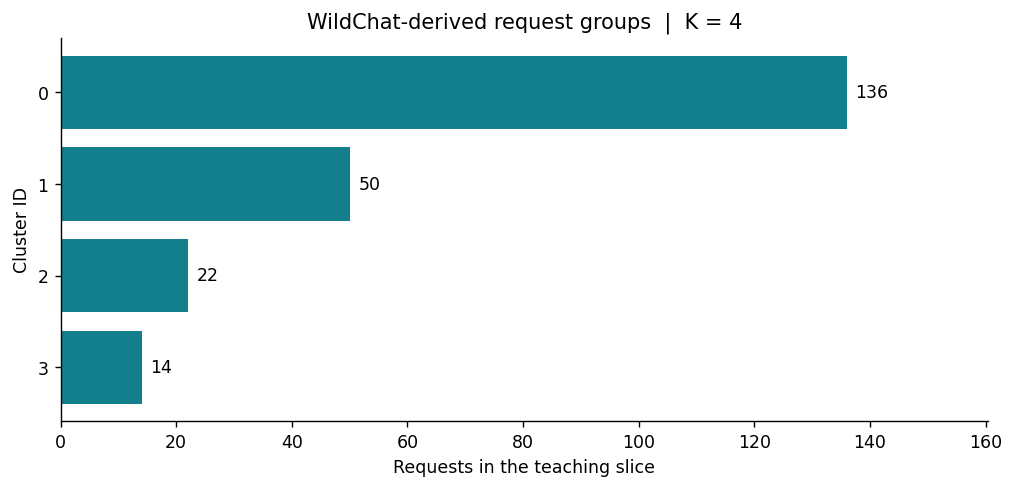

New cluster,Source cluster,Overlap rows
0,22,10
1,30,12
2,43,8
3,23,8


In [4]:
# Your turn · change K to 3 or 5 after the default run.
K = 4
assert K in {3, 4, 5}

vectorizer = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.80,
                             token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
X_prompt = vectorizer.fit_transform(prompt_table["user_prompt"])
with threadpool_limits(limits=1):
    km = KMeans(n_clusters=K, n_init=12, random_state=201).fit(X_prompt)
cluster = km.labels_
terms = vectorizer.get_feature_names_out()
top_words = [", ".join(terms[np.argsort(weights)[-5:][::-1]]) for weights in km.cluster_centers_]
clusters = pd.DataFrame({
    "Cluster": np.arange(K),
    "Rows": np.bincount(cluster, minlength=K),
    "Top terms": top_words,
})
display(clusters)

fig, ax = plt.subplots(figsize=(8.0, 3.8), layout="constrained")
bars = ax.barh(clusters["Cluster"].astype(str), clusters["Rows"], color="#137f8c")
ax.bar_label(bars, padding=5)
ax.set_xlim(0, clusters["Rows"].max() * 1.18)
ax.set(xlabel="Requests in the teaching slice", ylabel="Cluster ID", title=f"WildChat-derived request groups  |  K = {K}")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

# Optional check after fitting: overlap with the author's most common source group in each new cluster.
most_common = (
    pd.DataFrame({"New cluster": cluster, "Source cluster": prompt_table["cluster_id"]})
    .value_counts().rename("Overlap rows").reset_index()
    .sort_values(["New cluster", "Overlap rows", "Source cluster"], ascending=[True, False, True])
    .drop_duplicates("New cluster")
)
display(most_common.reset_index(drop=True))


## 3 Prediction for a held-out robot trajectory

The task is to classify whether the action is complete in a previously unseen frame. We load an ordered slice of 600 question–image pairs. Training keeps the completion question and binary references, excludes **the entire trajectory 14652**, and uses RGB pixels from the other trajectories. Each view is resized to 24 × 14 pixels, then flattened and scaled to [0, 1]. Classes receive inverse-frequency weights during the fit.

$$ p_i=\sigma(b+w^\top x_i)=\frac{1}{1+e^{-(b+w^\top x_i)}},\qquad
\widehat{y}_i=\mathbb{1}\{p_i\ge t\}. $$

Here $p_i$ is the fitted Yes score and $t$ is the decision threshold. For the default run $t=0.50$. The baseline labels both frames No. Compare their outputs and the reference labels. The two frames from one held-out trajectory illustrate an error. A benchmark would need many independent trajectories and uncertainty estimates.

**Your turn.** Change VIEW from **all** to **wrist** and rerun the fit. A separate option is to change THRESHOLD. A threshold chosen after looking at these two labels is exploratory and needs a fresh test set.

In [5]:
# Read and run once. Download only the filtered training images and the two test images.
def load_robot_page(offset):
    return [item["row"] for item in page(ROBOT, offset, first=(offset == 0))]

def trajectory(row):
    return row["id"].rsplit("_q", 1)[0]

def image_from_row(row):
    with Image.open(BytesIO(read_url(row["image"]["src"]))) as img:
        return img.convert("RGB")

with ThreadPoolExecutor(max_workers=6) as pool:
    rows = [row for batch in pool.map(load_robot_page, range(0, 600, 100)) for row in batch]
held_out = trajectory(targets[0])
assert all(trajectory(row) == held_out for row in targets)

training = [row for row in rows
            if trajectory(row) != held_out
            and row["question"].endswith("Has the robot successfully completed the task?")
            and reference_answer(row) in {"Yes", "No"}]
training_labels = [reference_answer(row) for row in training]
with ThreadPoolExecutor(max_workers=8) as pool:
    train_images = list(pool.map(image_from_row, training))
    test_images = list(pool.map(image_from_row, targets))

print(f"Rows read: {len(rows)}")
print(f"Training: {len(training)} labelled images from {len({trajectory(row) for row in training})} other trajectories")
print(f"Training labels: {dict(sorted(Counter(training_labels).items()))}")
print(f"Held-out trajectory: {held_out.rsplit('_', 1)[-1]}")


Rows read: 600
Training: 94 labelled images from 16 other trajectories
Training labels: {'No': 79, 'Yes': 15}
Held-out trajectory: 14652


In [6]:
# Your turn · change one setting after the default run.
VIEW = "all"  # "all" or "wrist"
THRESHOLD = 0.50  # a number strictly between 0 and 1
assert 0 < THRESHOLD < 1

def camera_view(img, view):
    if view == "all":
        return img
    if view == "wrist":
        width, height = img.size
        return img.crop((0, height // 2, width // 2, height))
    raise ValueError('Choose VIEW = "all" or VIEW = "wrist".')

def pixels(img, view):
    thumbnail = camera_view(img, view).resize((24, 14), Image.Resampling.BILINEAR)
    return np.asarray(thumbnail, dtype=np.float32).ravel() / 255

def fit_camera(view):
    x_train = np.stack([pixels(img, view) for img in train_images])
    x_test = np.stack([pixels(img, view) for img in test_images])
    labels = np.array([answer == "Yes" for answer in training_labels], dtype=int)
    classifier = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=0)
    with threadpool_limits(limits=1):
        classifier.fit(x_train, labels)
    yes_scores = classifier.predict_proba(x_test)[:, list(classifier.classes_).index(1)]
    return x_train, x_test, labels, classifier, yes_scores

X_train, X_test, y_train, model, scores = fit_camera(VIEW)
predictions = np.where(scores >= THRESHOLD, "Yes", "No")


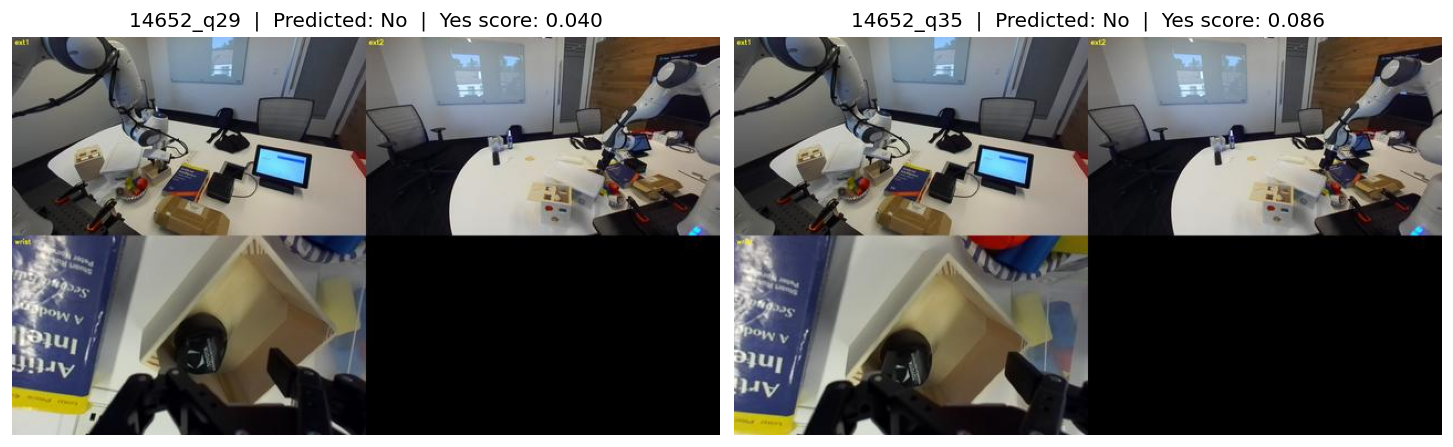

Record,Predicted,Yes score,Reference,Baseline,Matches reference
14652_q29,No,0.040,No,No,True
14652_q35,No,0.086,Yes,No,False


In [7]:
# Read and run. Compare the two predictions with the baseline and the reference.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, sample_id, img, prediction, score in zip(axes, TARGET_IDS, test_images, predictions, scores):
    ax.imshow(camera_view(img, VIEW))
    ax.set_title(f"{sample_id}  |  Predicted: {prediction}  |  Yes score: {score:.3f}")
    ax.set_axis_off()
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
plt.close(fig)
display(NotebookImage(data=buffer.getvalue()))

results = pd.DataFrame({
    "Record": TARGET_IDS,
    "Predicted": predictions,
    "Yes score": scores.round(3),
    "Reference": [reference_answer(row) for row in targets],
    "Baseline": ["No"] * len(TARGET_IDS),
})
results["Matches reference"] = results["Predicted"] == results["Reference"]
display(results)

## 4 Visualization gallery

Run this cell after the two fits. The gallery appears below and is also saved as **STATS201_Week3_Visualization_Gallery.png** in the Colab session.

| Panel | What it shows | What to inspect |
|---|---|---|
| A · Cluster geometry | scikit-learn TruncatedSVD projects the TF–IDF vectors and fitted centers to two dimensions. Seaborn draws the points. | Overlap in two dimensions can hide separation in the full fitted space. |
| B · Cluster themes | Seaborn displays selected term weights in the fitted K-means centers. | Read across each row and propose a tentative theme. |
| C · Held-out frames | Pillow and Matplotlib display the view used for each prediction, beside the reference and model labels. | Look for visible evidence of completion and cues the camera misses. |
| D · Decision scores | Matplotlib compares the two camera fits and marks your classification threshold. | Which setting changes the score? Which label is still missed? |

**Your turn.** Change K or VIEW, rerun its fit and this cell, and compare one panel with the default. Treat the scores as outputs for two frames from one trajectory. A fuller benchmark needs independent trajectories and a fresh test for any tuning decision.

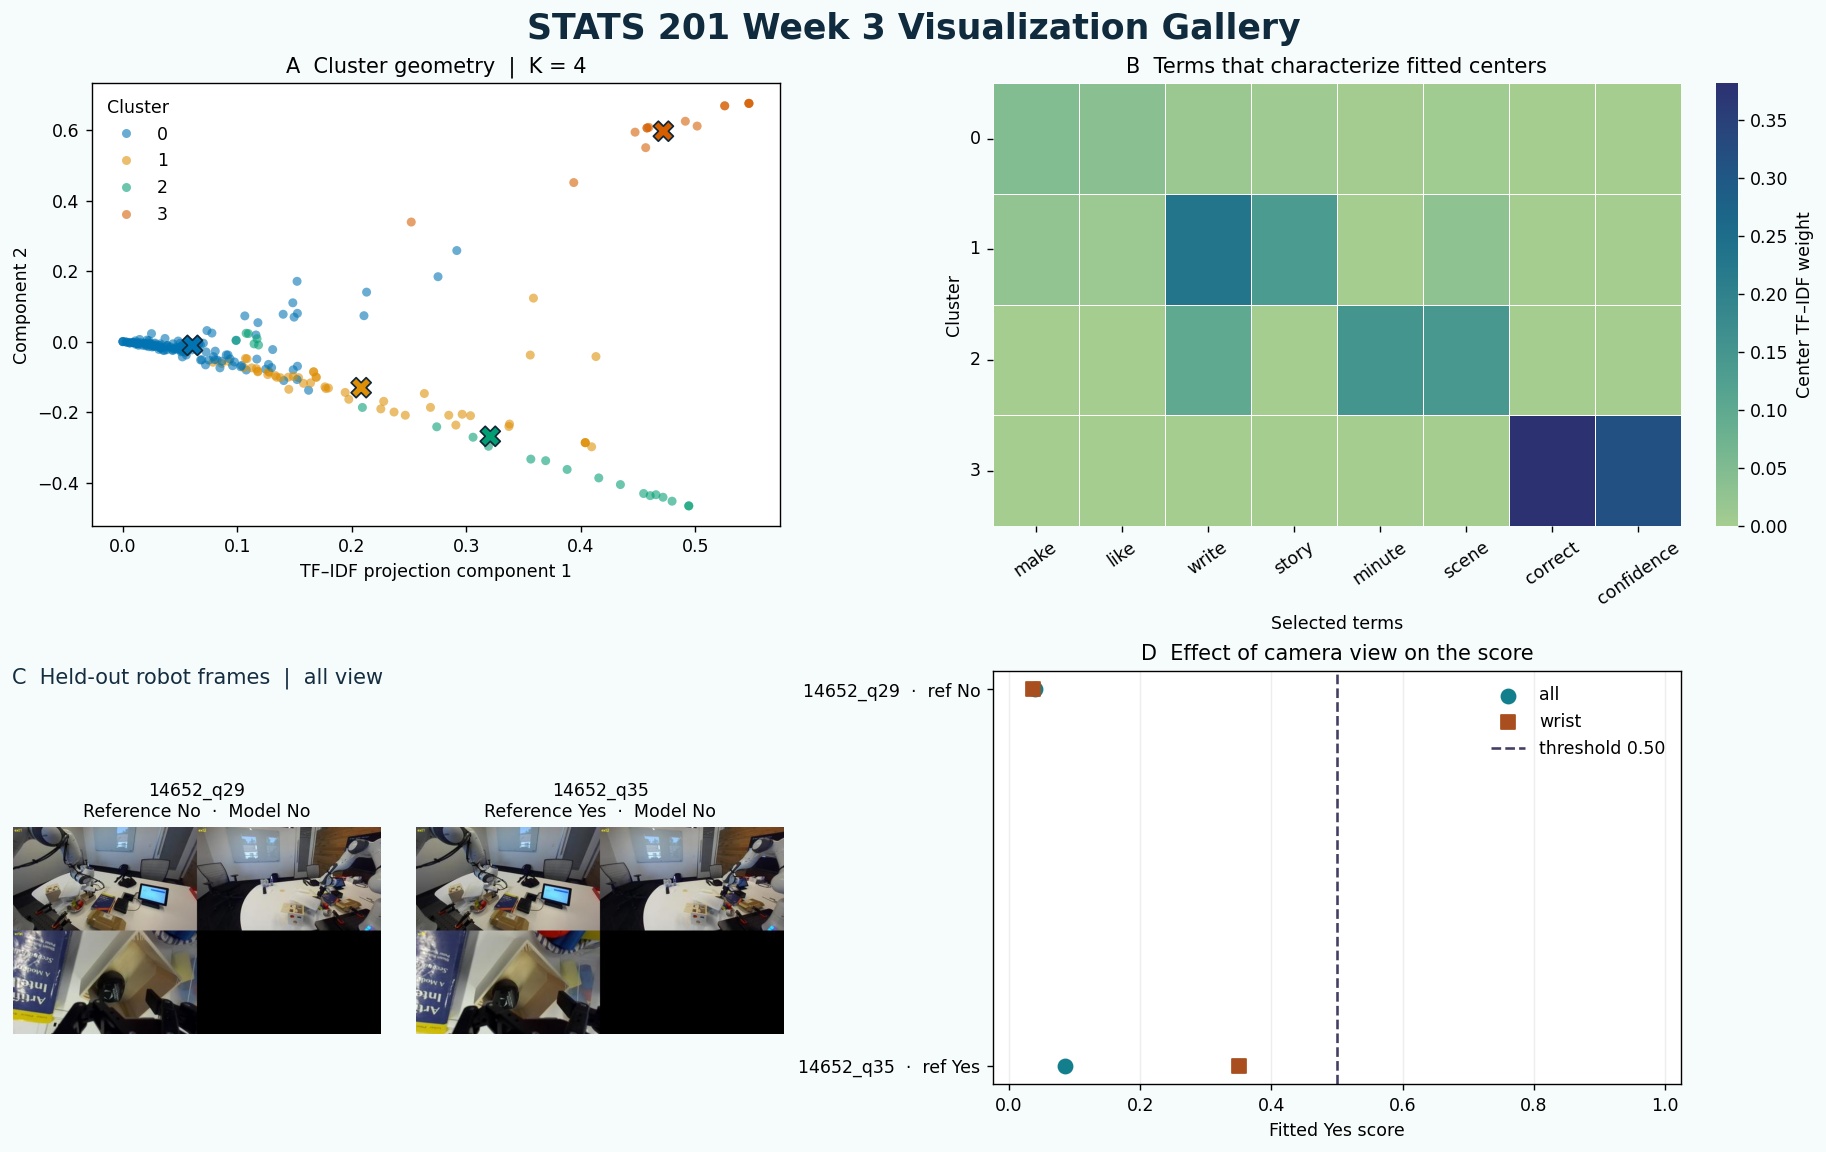

In [8]:
# Generate and display the gallery from the current fitted models.
def make_gallery(filename="STATS201_Week3_Visualization_Gallery.png"):
    with threadpool_limits(limits=1):
        projector = TruncatedSVD(n_components=2, random_state=201).fit(X_prompt)
        projected = projector.transform(X_prompt)
        centers = projector.transform(km.cluster_centers_)
    palette = sns.color_palette("colorblind", K)
    refs = [reference_answer(row) for row in targets]
    other_view = "wrist" if VIEW == "all" else "all"
    score_by_view = {VIEW: scores, other_view: fit_camera(other_view)[-1]}
    terms_to_show = list(dict.fromkeys(
        int(i) for center in km.cluster_centers_ for i in np.argsort(center)[-2:][::-1]
    ))
    vocabulary = vectorizer.get_feature_names_out()
    weights = pd.DataFrame(km.cluster_centers_[:, terms_to_show],
                           columns=vocabulary[terms_to_show], index=np.arange(K))
    fig = plt.figure(figsize=(14.5, 9.1), layout="constrained", facecolor="#f6fbfb")
    layout = fig.add_gridspec(2, 2, height_ratios=[1.07, 1.0])
    a = fig.add_subplot(layout[0, 0])
    b = fig.add_subplot(layout[0, 1])
    camera_row = layout[1, 0].subgridspec(2, 2, height_ratios=[0.16, 1])
    c_title = fig.add_subplot(camera_row[0, :])
    c0, c1 = fig.add_subplot(camera_row[1, 0]), fig.add_subplot(camera_row[1, 1])
    d = fig.add_subplot(layout[1, 1])

    sns.scatterplot(x=projected[:, 0], y=projected[:, 1], hue=cluster.astype(str),
                    hue_order=[str(j) for j in range(K)], palette=palette, ax=a,
                    alpha=.58, s=27, linewidth=0)
    a.scatter(centers[:, 0], centers[:, 1], c=palette, marker="X",
              s=133, edgecolor="#122838", linewidth=1.0, label="_nolegend_")
    a.set(title=f"A  Cluster geometry  |  K = {K}",
          xlabel="TF–IDF projection component 1", ylabel="Component 2")
    a.legend(title="Cluster", loc="best", frameon=False)

    sns.heatmap(weights, cmap="crest", ax=b, linewidths=.5,
                cbar_kws={"label":"Center TF–IDF weight"})
    b.set(title="B  Terms that characterize fitted centers", xlabel="Selected terms", ylabel="Cluster")
    b.tick_params(axis="x", labelrotation=35)
    b.tick_params(axis="y", labelrotation=0)

    c_title.set_axis_off()
    c_title.text(0, .40, f"C  Held-out robot frames  |  {VIEW} view", fontsize=12,
                 color="#152d40", fontweight="medium")
    for axis, img, label, expected, prediction in zip((c0, c1), test_images, TARGET_IDS, refs, predictions):
        axis.imshow(camera_view(img, VIEW))
        axis.set_title(f"{label}\nReference {expected}  ·  Model {prediction}", fontsize=10)
        axis.set_axis_off()

    for view, marker, tint in (("all","o","#137f8c"),("wrist","s","#a94e1f")):
        d.scatter(score_by_view[view], [0, 1], marker=marker, color=tint, s=66, label=view)
    d.axvline(THRESHOLD, color="#453e63", linestyle="--", label=f"threshold {THRESHOLD:.2f}")
    d.set(xlim=(-.025, 1.025), yticks=[0, 1],
          yticklabels=[f"{key}  ·  ref {ref}" for key,ref in zip(TARGET_IDS,refs)],
          xlabel="Fitted Yes score", title="D  Effect of camera view on the score")
    d.invert_yaxis()
    d.grid(axis="x", alpha=.22)
    d.legend(frameon=False, loc="best")
    fig.suptitle("STATS 201 Week 3 Visualization Gallery", fontsize=20, color="#102b3d", fontweight="bold")
    if filename is not None:
        fig.savefig(filename, dpi=165, facecolor=fig.get_facecolor(), bbox_inches="tight")
    show_figure(fig)

make_gallery()


## Research transfer

- Measurement. Which label definition or observation unit does your project need to document?
- Explanation. Describe one group that the algorithm found and check whether the interpretation survives a different K. The cluster structure is exploratory.
- Prediction. Identify the unit you would hold out to prevent nearby observations from leaking into training. Name one error that would matter in practice.
- Benchmark. State your comparison, baseline and metric, then specify whose outcomes or conditions should be checked separately.

**Sources and scope.** Chen et al. (2025), [Robo2VLM](https://arxiv.org/abs/2505.15517) and [Robo2VLM-1](https://huggingface.co/datasets/keplerccc/Robo2VLM-1). Zhao et al. (2024), [WildChat](https://arxiv.org/abs/2405.01470). Shen (2025), [ICML paper and Appendix A.2](https://proceedings.mlr.press/v267/shen25r.html) and [author's public WildChat-derived table](https://huggingface.co/datasets/heyyjudes/wildchat-creative-only-labeled). The table has no separate license field at the checked revision, so this notebook fetches the data in place and shares only aggregate terms and figures. The fitted models and figures are classroom results. [TabArena](https://arxiv.org/abs/2506.16791) provides the benchmark design reading.